<div style="background:#1B2A49; border-left:12px solid #C8102E; border-radius:16px; padding:40px; text-align:center; color:white;">

<img src="https://moria.aurens.com/organizations/497d3acf-35c0-4c90-8754-d5e71162119b/logos/3215d7-271.png" width="240" style="background:white; padding:10px; border-radius:10px;">

<h1 style="color:white; margin-top:20px;">Colegio Universitario de Cartago</h1>
<h2 style="color:#F2A900;">Minería de Datos II</h2>
<h3 style="color:white;">Examen 2</h3>

<hr style="border-color:#F2A900;">

<p><b style="color:#F2A900;">Profesor:</b> Ronald Códoba Vega</p>
<p><b style="color:#F2A900;">Integrantes:</b><br>Johel Barquero Carvajal<br>Sharon Obando Gómez<br>Fabián Brenes Loría<br>Steven Vindas Rivera<br>Marisol Víquez Rivera</p>
<p><b style="color:#F2A900;">Fecha de entrega:</b> 10 de noviembre de 2026</p>

</div>

--------------------

#### Justificación del tamaño de la muestra

Para las reglas de asociación se usó una muestra de **2,000 registros**. Se seleccionaron facturas completas con semilla fija para conservar cada canasta de compra y poder reproducir la muestra.

**¿Por qué una muestra?** Los algoritmos Apriori, ECLAT y FP-Growth son costosos con más de 500 mil registros. Con 2,000 se ejecutan en segundos, se pueden comparar entre sí y generan una cantidad de reglas que sí se puede interpretar (318 itemsets y 370 reglas con soporte 3 y confianza 0,5).

**CRISP-DM y EDA** se hicieron con el conjunto completo, porque ahí interesa describir el negocio y la calidad de los datos, y las estadísticas son más confiables con toda la información.

--------------------------

#### 1. Importamos las clases de las Reglas de Asociación

In [ ]:
import sys, os
sys.path.append(os.path.abspath(".."))   # sube de reporte_final a la raíz del proyecto

# from reglas_asociacion.apriori import Apriori
from reglas_asociacion.eclat import Eclat
# from reglas_asociacion.fpgrowth import FPGrowth

-------

#### 2. Regla de Asociación: Apriori

----

#### 3. Regla de Asociación: ECLAT

In [ ]:
# Llamado al modelo Eclat para generar reglas de asociación

modelo = Eclat(min_support=3, min_confidence=0.5)
modelo.load_csv("../processed/2mil_online_retail.csv", transaction_col="InvoiceNo", item_col="Description")
modelo.fit()
reglas = modelo.generate_rules()

print("Transacciones:           ", len(modelo.transactions))
print("Productos distintos:     ", len(modelo.item_tidset))
print("Soporte mínimo (abs):    ", modelo.min_support)
print("Itemsets frecuentes:     ", len(modelo.frequent_itemsets))
print("Reglas generadas:        ", len(modelo.rules))

Transacciones:            90
Productos distintos:      1126
Soporte mínimo (abs):     3
Itemsets frecuentes:      318
Reglas generadas:         370


**Interpretación:** La muestra contiene 90 facturas con 1,126 productos distintos. Con un soporte mínimo de 3 facturas, el algoritmo ECLAT encontró 318 itemsets frecuentes (productos solos y combinaciones que se compran juntos) y generó 370 reglas de asociación con confianza mínima de 0,5. Como la mayoría de los productos aparece en muy pocas facturas, los patrones son ilustrativos por el tamaño reducido de la muestra.

In [ ]:
# Aqui se muestran los 15 itemsets frecuentes más grandes (por soporte) que tengan al menos 2 items

combos = [(sorted(k), v) for k, v in modelo.frequent_itemsets.items() if len(k) >= 2]
for items, sup in sorted(combos, key=lambda x: -x[1])[:15]:
    print(sup, "facturas ->", " + ".join(items))

5 facturas -> PARTY BUNTING + SPOTTY BUNTING
5 facturas -> PARTY BUNTING + REGENCY CAKESTAND 3 TIER
5 facturas -> JUMBO BAG VINTAGE DOILY + LUNCH BAG VINTAGE DOILY
4 facturas -> PARTY BUNTING + WHITE HANGING HEART T-LIGHT HOLDER
4 facturas -> LUNCH BAG VINTAGE DOILY + SPOTTY BUNTING
4 facturas -> JUMBO BAG VINTAGE DOILY + SPOTTY BUNTING
4 facturas -> CHOCOLATE HOT WATER BOTTLE + HOT WATER BOTTLE TEA AND SYMPATHY
4 facturas -> 60 TEATIME FAIRY CAKE CASES + PACK OF 72 RETROSPOT CAKE CASES
4 facturas -> 72 SWEETHEART FAIRY CAKE CASES + PACK OF 72 RETROSPOT CAKE CASES
4 facturas -> 60 TEATIME FAIRY CAKE CASES + 72 SWEETHEART FAIRY CAKE CASES
4 facturas -> COOK WITH WINE METAL SIGN + PLEASE ONE PERSON METAL SIGN
4 facturas -> WOOD 2 DRAWER CABINET WHITE FINISH + WOOD S/3 CABINET ANT WHITE FINISH
4 facturas -> ALARM CLOCK BAKELIKE GREEN + ALARM CLOCK BAKELIKE PINK
3 facturas -> PARTY BUNTING + SWEETHEART CAKESTAND 3 TIER
3 facturas -> LOVE BUILDING BLOCK WORD + PARTY BUNTING


In [14]:
# Aqui se muestran las 15 reglas de asociación más fuertes (por confianza) que tengan al menos 2 items en el antecedente y 1 item en el consecuente

reglas.head(15)

,antecedente,consecuente,soporte,confianza,lift
0,"[LUNCH BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...","[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOI...",0.0333,1.0,30.0
1,"[JAM MAKING SET PRINTED, LUNCH BAG VINTAGE DOILY]","[JUMBO BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...",0.0333,1.0,30.0
2,"[JAM MAKING SET PRINTED, SET OF 4 KNICK KNACK ...","[JUMBO BAG VINTAGE DOILY, LUNCH BAG VINTAGE DO...",0.0333,1.0,30.0
3,"[JUMBO BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...","[JAM MAKING SET PRINTED, LUNCH BAG VINTAGE DOI...",0.0333,1.0,30.0
4,"[SET OF 4 KNICK KNACK TINS DOILY, SPOTTY BUNTING]","[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOI...",0.0333,1.0,30.0
5,"[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOILY]","[LUNCH BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...",0.0333,1.0,30.0
6,"[JAM MAKING SET PRINTED, SPOTTY BUNTING]","[JUMBO BAG VINTAGE DOILY, LUNCH BAG VINTAGE DO...",0.0333,1.0,30.0
7,"[JUMBO BAG VINTAGE DOILY, LUNCH BAG VINTAGE DO...","[JAM MAKING SET PRINTED, SPOTTY BUNTING]",0.0333,1.0,30.0
8,"[LUNCH BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...","[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOILY]",0.0333,1.0,30.0
9,"[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOI...","[SET OF 4 KNICK KNACK TINS DOILY, SPOTTY BUNTING]",0.0333,1.0,30.0


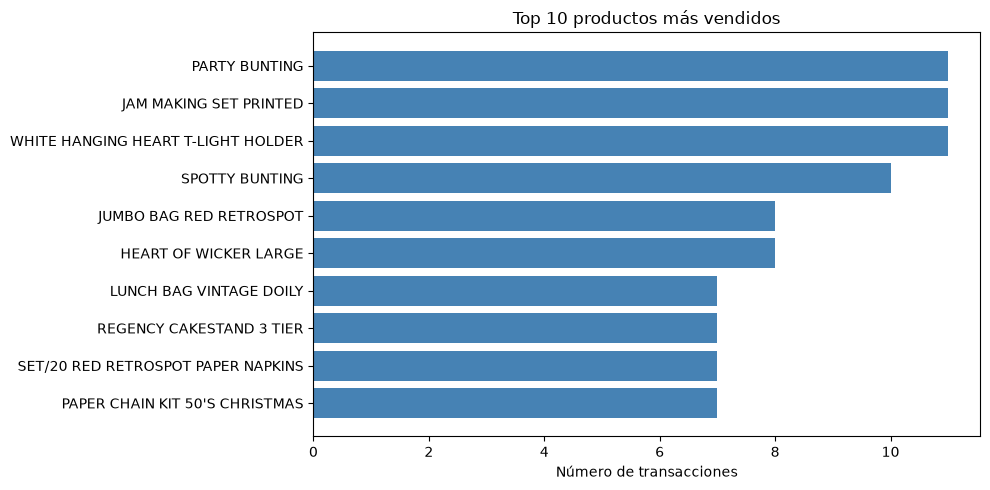

In [ ]:
# Grafica el TOP 10 de productos mas vendidos

modelo.plot_top_items()

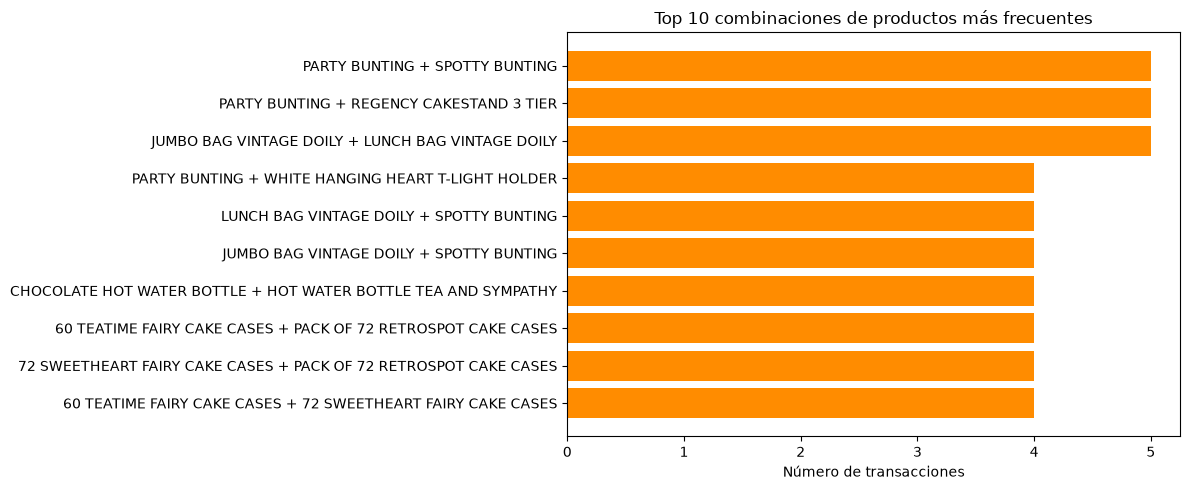

In [ ]:
# Grafica el TOP 10 de las combinaciones de productos más frecuentes (itemsets) que tengan al menos 2 items

modelo.plot_top_itemsets()

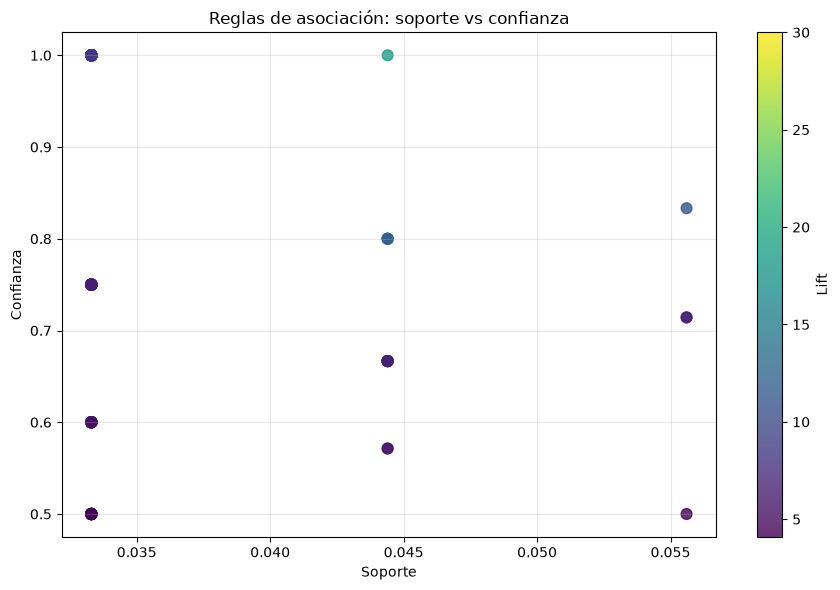

In [ ]:
# Grafica las reglas de asociación con confianza mayor a 0.5 y soporte mayor a 0.01

modelo.plot_rules()

----

#### 4. Regla de Asociación: FP-Growth